In [ ]:
#Imports
!pip install -q huggingface_hub opencv-python scikit-image scikit-learn pandas

In [ ]:
import os,glob,json,zipfile
import numpy as np
import pandas as pd
import cv2
from skimage.feature import hog
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit,StratifiedGroupKFold,GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier,VotingClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [ ]:
# Downloading the data and unzipping it

from huggingface_hub import list_repo_files, hf_hub_download

REPO = "keycxl/DENTEX"


repo_files = list_repo_files(REPO, repo_type="dataset")
print([f for f in repo_files if f.endswith(".zip")])
zip_name = [f for f in repo_files if f.endswith("training_data.zip")][0]


zip_path = hf_hub_download(REPO, zip_name, repo_type="dataset", local_dir="dentex_data")
print("downloaded to:", zip_path)

if not os.path.exists("dentex_train"):
    zipfile.ZipFile(zip_path).extractall("dentex_train")

print(glob.glob("dentex_train/*"))

['DENTEX/test_data.zip', 'DENTEX/training_data.zip', 'DENTEX/validation_data.zip']


DENTEX/training_data.zip: reconstructing file:   0%|          |  0.00B / 10.9GB            

DENTEX/training_data.zip: downloading bytes:           |  0.00B            

downloaded to: /content/dentex_data/DENTEX/training_data.zip
['dentex_train/training_data']


In [ ]:
# Annotation files

for p in sorted(glob.glob("dentex_train/**/*.json",recursive = True)):
  print(p)

dentex_train/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json
dentex_train/training_data/quadrant/train_quadrant.json
dentex_train/training_data/quadrant_enumeration/train_quadrant_enumeration.json


In [ ]:
jsons = glob.glob("dentex_train/**/*.json",recursive = True)
quad_json = [p for p in jsons if p.endswith("train_quadrant.json")][0]
enum_json = [p for p in jsons if p.endswith("train_quadrant_enumeration.json")][0]
dis_json = [p for p in jsons if p.endswith("train_quadrant_enumeration_disease.json")][0]

print(quad_json,enum_json,dis_json,sep="\n")

dentex_train/training_data/quadrant/train_quadrant.json
dentex_train/training_data/quadrant_enumeration/train_quadrant_enumeration.json
dentex_train/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json


In [ ]:
for path in [quad_json,enum_json,dis_json]:
  d = json.load(open(path))
  print(os.path.basename(path),"->",len(d["images"]),"images",len(d["annotations"]))
  print(" annotation keys:",list(d["annotations"][0].keys()))

  for k,v in d.items():
    if k.startswith("categories"):
      print(" ",k,[c["name"] for c in v])

train_quadrant.json -> 693 images 2772
 annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'category_id', 'id', 'area']
  categories ['2', '1', '3', '4']
train_quadrant_enumeration.json -> 634 images 18095
 annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'id', 'area', 'category_id_1', 'category_id_2']
  categories_1 [1, 2, 3, 4]
  categories_2 ['1', '2', '3', '4', '5', '6', '7', '8']
train_quadrant_enumeration_disease.json -> 705 images 3529
 annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'id', 'area', 'category_id_1', 'category_id_2', 'category_id_3']
  categories_1 ['1', '2', '3', '4']
  categories_2 ['1', '2', '3', '4', '5', '6', '7', '8']
  categories_3 ['Impacted', 'Caries', 'Periapical Lesion', 'Deep Caries']


In [ ]:
quad_key,quad_cat = "category_id" , "categories"
enum_key,enum_cat = "category_id_2" , "categories_2"
dis_key,dis_cat = "category_id_3","categories_3"

def build_df(json_path,label_key,cat_key):
  data = json.load(open(json_path))

  # Each task has its own xrays folders.

  folder = os.path.dirname(json_path)
  img_paths = {}

  for p in glob.glob(folder + "/**/*",recursive = True):
    if p.lower().endswith((".png",".jpg",".jpeg")):
      img_paths[os.path.basename(p)] = p

  id2name = {c["id"]: str(c["name"]) for c in data[cat_key]}
  images = {im["id"] : im for im in data["images"]}

  rows = []
  for a in data["annotations"]:
    im = images[a["image_id"]]
    rows.append({
        "image_id" : a["image_id"],
        "file": im["file_name"],
        "W" : im["width"],
        "H" : im["height"],
        "bbox" : a["bbox"],
        "label" : a[label_key],
        "label_name" : id2name[a[label_key]],
    })

  df = pd.DataFrame(rows).sort_values("file").reset_index(drop=True)
  return df,img_paths

df_quad,paths_quad = build_df(quad_json,quad_key,quad_cat)
df_enum,paths_enum = build_df(enum_json,enum_key,enum_cat)
df_dis,paths_dis = build_df(dis_json,dis_key,dis_cat)

for name,df,paths in [("quadrant",df_quad,paths_quad),
                      ("enumeration",df_enum,paths_enum),
                      ("disease",df_dis,paths_dis)]:
    print(name,"| boxes:",len(df),"| images:",df["image_id"].nunique(),"| image files found:",len(paths))
    print(" classes:",df["label_name"].value_counts().sort_index().to_dict())


quadrant | boxes: 2772 | images: 693 | image files found: 693
 classes: {'1': 693, '2': 693, '3': 693, '4': 693}
enumeration | boxes: 18095 | images: 634 | image files found: 634
 classes: {'1': 2508, '2': 2497, '3': 2499, '4': 2404, '5': 2299, '6': 2070, '7': 2314, '8': 1504}
disease | boxes: 3529 | images: 678 | image files found: 705
 classes: {'Caries': 2189, 'Deep Caries': 578, 'Impacted': 604, 'Periapical Lesion': 158}


In [ ]:
df_quad.head()

,image_id,file,W,H,bbox,label,label_name
0,54,train_0.png,2955,1316,"[601.0, 478.375, 900.0, 518.75]",3,4
1,54,train_0.png,2955,1316,"[1491.625, 494.0, 837.5, 503.125]",2,3
2,54,train_0.png,2955,1316,"[697.875, 281.5, 775.0, 371.875]",1,1
3,54,train_0.png,2955,1316,"[1466.625, 256.5, 800.0, 390.625]",0,2
4,432,train_1.png,2847,1316,"[501.7058823529411, 566.1764705882351, 923.529...",3,4


In [ ]:
df_enum.head()

,image_id,file,W,H,bbox,label,label_name
0,46,train_0.png,2955,1316,"[1617.764705882353, 282.11764705882354, 105.88...",2,3
1,46,train_0.png,2955,1316,"[1376.5882352941176, 288.0, 102.94117647058829...",0,1
2,46,train_0.png,2955,1316,"[1303.0588235294117, 293.88235294117646, 85.29...",1,2
3,46,train_0.png,2955,1316,"[1241.2941176470588, 255.6470588235294, 85.294...",2,3
4,46,train_0.png,2955,1316,"[1167.764705882353, 217.41176470588232, 114.70...",3,4


In [ ]:
df_dis.head()

,image_id,file,W,H,bbox,label,label_name
0,57,train_0.png,2850,1316,"[1791.0, 445.72727272727263, 147.4545454545452...",1,Caries
1,57,train_0.png,2850,1316,"[682.090909090909, 687.5454545454545, 200.0, 3...",1,Caries
2,442,train_1.png,2750,1316,"[729.6296296296296, 713.5802469135803, 166.666...",0,Impacted
3,442,train_1.png,2750,1316,"[1978.125, 723.9583333333334, 144.791666666666...",0,Impacted
4,198,train_10.png,2837,1316,"[1988.0, 784.0, 166.0, 238.0]",1,Caries


In [ ]:
# feature Extraction

clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
def get_features(df,img_paths):

  features = []
  current_file = None
  img = None

  for row in df.itertuples():
    if row.file != current_file:
      img = cv2.imread(img_paths[row.file],cv2.IMREAD_GRAYSCALE)
      current_file = row.file

    x, y, w, h = [int(v) for v in row.bbox]
    x,y = max(x,0),max(y,0)

    crop = img[y:y + max(h,1), x:x+max(w,1)]
    crop = cv2.resize(crop,(64,64))

    crop = clahe.apply(crop)

    hog_feat = hog(crop,orientations = 9,pixels_per_cell=(8,8),cells_per_block = (2,2))
    pos = [(x+w/2) / row.W , (y+h/2)/row.H , w/row.W , h/row.H]
    features.append(np.concatenate([hog_feat,pos]))


  return np.array(features)


X_quad = get_features(df_quad,paths_quad)
X_enum = get_features(df_enum,paths_enum)
X_dis = get_features(df_dis,paths_dis)

print(X_quad.shape,X_enum.shape,X_dis.shape)

(2772, 1768) (18095, 1768) (3529, 1768)


In [ ]:
# 3 separate train/test splits

tasks = {
    "quadrant" : {"df": df_quad , "X" : X_quad},
    "enumeration" : {"df":df_enum,"X" : X_enum},
    "disease" : {"df":df_dis , "X" : X_dis},
}

for name,t in tasks.items():
  groups = t["df"]["image_id"].values
  splitter = GroupShuffleSplit(n_splits=1,test_size =0.3,random_state = 42)
  train,test = next(splitter.split(t["X"] , groups = groups))
  t["train"] , t["test"] , t["groups"] = train,test,groups

  pd.Series(sorted(set(groups[test]))).to_csv(f"test_ids_{name}.csv",index=False,header=["image_id"])
  print(name,"train teeth:",len(train),"test teeth:",len(test))

quadrant train teeth: 1940 test teeth: 832
enumeration train teeth: 12610 test teeth: 5485
disease train teeth: 2468 test teeth: 1061


In [ ]:
# MODELS AND GRIDS

models_quad = {
    "logreg" : make_pipeline(StandardScaler() ,
                             LogisticRegression(max_iter = 150,C = 0.01,class_weight = "balanced")),
    "svm" : make_pipeline(StandardScaler(),
                          PCA(n_components=0.95, random_state=42),
                          SVC(probability = True , class_weight = "balanced",C = 1 , gamma = "scale",kernel = "rbf")),
    "rf" : RandomForestClassifier(class_weight="balanced",random_state = 42,max_depth= None , n_estimators =  400),
    "knn" : make_pipeline(StandardScaler() , PCA(random_state=42,n_components = 0.9) , KNeighborsClassifier(n_neighbors = 9))

}

models_enum = {
    "logreg" : make_pipeline(StandardScaler() ,
                             LogisticRegression(max_iter = 150,C=0.005,class_weight = "balanced")),
    "svm" : make_pipeline(StandardScaler(),
                          PCA(n_components=0.95, random_state=42),
                          SVC(probability = True , class_weight = "balanced", C = 1 , gamma = "scale" , kernel = "rbf")),
    "rf" : RandomForestClassifier(class_weight="balanced",random_state = 42,max_depth = 20,n_estimators = 400),
    "knn" : make_pipeline(StandardScaler() , PCA(random_state=42,n_components = 0.95) , KNeighborsClassifier(n_neighbors = 9))
}

models_dis = {
    "logreg" : make_pipeline(StandardScaler() ,
                             LogisticRegression(max_iter = 150 ,C = 0.005,class_weight = "balanced")),
    "svm" : make_pipeline(StandardScaler(),
                          PCA(n_components=0.95, random_state=42),
                          SVC(probability = True , class_weight = "balanced", C = 1 , gamma = "scale" , kernel = "rbf")),
    "rf" : RandomForestClassifier(class_weight="balanced",random_state = 42,max_depth = 20,n_estimators=200),
    "knn" : make_pipeline(StandardScaler() , PCA(random_state=42,n_components=0.9) , KNeighborsClassifier(n_neighbors=3))
}



In [ ]:
# Voting ensemble

model_sets = {"quadrant": models_quad, "enumeration": models_enum, "disease": models_dis}

best_models = {}

for task, t in tasks.items():
    X_train = t["X"][t["train"]]
    y_train = t["df"]["label"].values[t["train"]]

    members = list(model_sets[task].items())   # [(name, pipeline), ...]
    vote = VotingClassifier(members, voting="soft")
    vote.fit(X_train, y_train)

    best_models[(task, "voting")] = vote
    print(task, "voting fitted")

quadrant voting fitted
enumeration voting fitted
disease voting fitted


In [ ]:
results = []
for (task, name), model in best_models.items():
    t = tasks[task]
    X_test = t["X"][t["test"]]
    y_test = t["df"]["label"].values[t["test"]]
    pred = model.predict(X_test)
    results.append({
        "task": task, "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "f1": f1_score(y_test, pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(results).round(3)
results.to_csv("classical_results.csv", index=False)
print(results.pivot(index="model", columns="task", values="f1"))
results

task    disease  enumeration  quadrant
model                                 
voting    0.493        0.608     0.995


,task,model,accuracy,precision,recall,f1
0,quadrant,voting,0.995,0.995,0.995,0.995
1,enumeration,voting,0.604,0.609,0.611,0.608
2,disease,voting,0.767,0.697,0.504,0.493


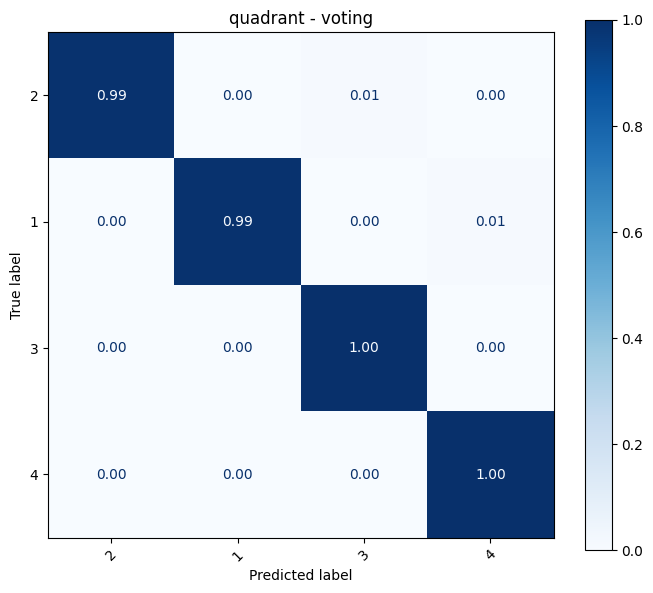

              precision    recall  f1-score   support

           2       1.00      0.99      1.00       208
           1       1.00      0.99      1.00       208
           3       0.99      1.00      1.00       208
           4       0.99      1.00      1.00       208

    accuracy                           1.00       832
   macro avg       1.00      1.00      1.00       832
weighted avg       1.00      1.00      1.00       832



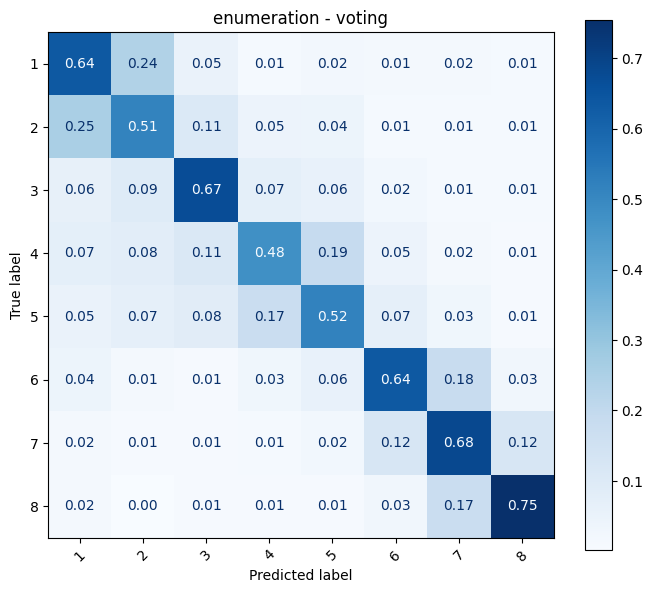

              precision    recall  f1-score   support

           1       0.57      0.64      0.60       760
           2       0.51      0.51      0.51       753
           3       0.65      0.67      0.66       749
           4       0.58      0.48      0.52       720
           5       0.56      0.52      0.54       698
           6       0.65      0.64      0.64       632
           7       0.64      0.68      0.66       688
           8       0.72      0.75      0.74       485

    accuracy                           0.60      5485
   macro avg       0.61      0.61      0.61      5485
weighted avg       0.60      0.60      0.60      5485



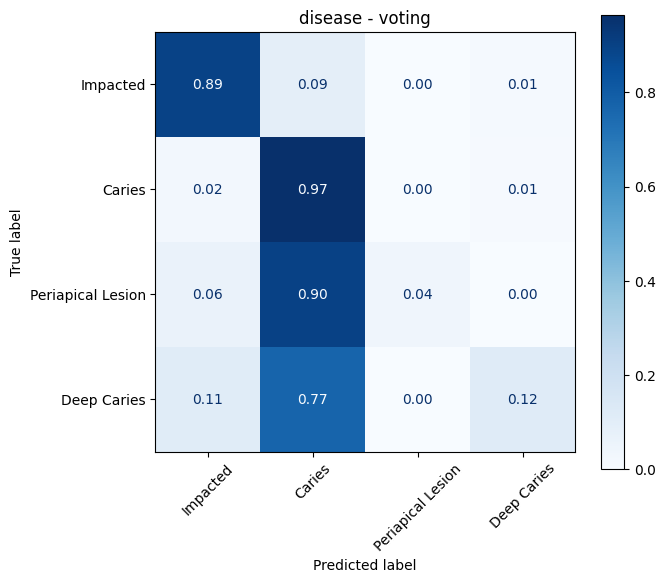

                   precision    recall  f1-score   support

         Impacted       0.80      0.89      0.84       170
           Caries       0.76      0.97      0.85       662
Periapical Lesion       0.50      0.04      0.08        49
      Deep Caries       0.72      0.12      0.20       180

         accuracy                           0.77      1061
        macro avg       0.70      0.50      0.49      1061
     weighted avg       0.75      0.77      0.70      1061



In [ ]:
def show_confusion(task, model_name, normalize=None):
    t = tasks[task]
    model = best_models[(task, model_name)]

    X_test = t["X"][t["test"]]
    y_test = t["df"]["label"].values[t["test"]]
    pred = model.predict(X_test)

    id2name = dict(zip(t["df"]["label"], t["df"]["label_name"]))
    labels = sorted(id2name)
    names = [id2name[l] for l in labels]

    cm = confusion_matrix(y_test, pred, labels=labels, normalize=normalize)
    disp = ConfusionMatrixDisplay(cm, display_labels=names)

    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45,
              values_format=".2f" if normalize else "d")
    ax.set_title(f"{task} - {model_name}")
    plt.tight_layout()
    plt.show()

    print(classification_report(y_test, pred, labels=labels,
                                target_names=names, zero_division=0))

for task in tasks:
    show_confusion(task, "voting", normalize="true")